# DINOv2 and LeVJEPA on London

[DINOv2](https://arxiv.org/abs/2304.07193) ([code](https://github.com/facebookresearch/dinov2)) learns image features by self-distillation. A student network matches the prototype assignments of an EMA teacher: its `[cls]` token from every crop matches the teacher's on the other global crops (**DINO**), its masked patches match the teacher's unmasked ones (**iBOT**), and **KoLeo** spreads its embeddings. The teacher's scores are centered by Sinkhorn-Knopp so no prototype dominates.

[LeVJEPA](levjepa.ipynb) learns video features with no teacher: local views of a clip predict its global view, and SIGReg keeps the embeddings Gaussian. Here both train on the same London photos and street footage, with the same ViT, steps, batch and color jitter. DINOv2 sees single frames and LeVJEPA 8-frame clips, each as its method prescribes.

In [1]:
import base64
import io
import math
import time

import av
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import HTML
from IPython.display import Image as Picture
from PIL import Image, ImageDraw, ImageFont
from torch import nn

from torch_world import metrics, plots
from torch_world.masks import BlockwiseMask
from torch_world.models import DINOHead, DINOv2, DINOv2Encoder, LeVJEPA, LeVJEPAEncoder
from torch_world.nn import MLP
from torch_world.utils import recompute_batchnorm

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
FRAMES, STRIDE = 8, 2  # frames per clip, taking every second frame of the footage
SIZE, PATCH = 128, 8  # crop side and patch side, in pixels
STEPS, BATCH = 1500, 128
VIT = dict(patch_size=PATCH, embed_dim=192, depth=6, num_heads=6)  # the same ViT for both models


def jpeg(fig):
    """A figure as a JPEG, much smaller than PNG for photographs."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="jpg", dpi=200, pil_kwargs={"quality": 90})
    return Picture(buffer.getvalue())


def title_bar(title, width, height=48):
    """A white bar (3, height, width) with title centered, in the color of figure titles."""
    bar = Image.new("RGB", (width, height), "white")
    ImageDraw.Draw(bar).text((width / 2, height / 2), title, fill=plots.INK_2, font=ImageFont.load_default(26), anchor="mm")
    return torch.from_numpy(np.array(bar)).permute(2, 0, 1).float().div(255)


def video(panels, fps=6):
    """An MP4 of panels {title: frames (T, 3, H, W) in [0, 1]}, side by side under their titles."""
    first = next(iter(panels.values()))
    T, W = len(first), first.size(-1)
    titled = [torch.cat([title_bar(title, W).expand(T, -1, -1, -1), frames.cpu()], dim=-2) for title, frames in panels.items()]
    gap = torch.ones(T, 3, titled[0].size(-2), 8)
    strip = torch.cat([x for panel in titled for x in (panel, gap)][:-1], dim=-1)
    buffer = io.BytesIO()
    with av.open(buffer, "w", format="mp4") as container:
        stream = container.add_stream("libx264", rate=fps, options={"crf": "20"})
        stream.width, stream.height, stream.pix_fmt = strip.size(-1), strip.size(-2), "yuv420p"
        for frame in strip.mul(255).byte().permute(0, 2, 3, 1).numpy():
            container.mux(stream.encode(av.VideoFrame.from_ndarray(frame, format="rgb24")))
        container.mux(stream.encode())
    data = base64.b64encode(buffer.getvalue()).decode()
    return HTML(f'<video autoplay loop muted playsinline controls style="width: 100%" src="data:video/mp4;base64,{data}"></video>')

## London
The clips of the [LeVJEPA notebook](levjepa.ipynb): a window that pans over one of three photographs, or a fixed window on the street footage while the traffic moves. Each clip is labeled with its scene, and with its region: the scene and the left, middle or right third of the positions the window can take.

In [2]:
SCENES = {"fox": "fox.jpg", "Tower Bridge": "tower-bridge.jpg", "UCL portico": "ucl-portico.jpg", "street": "street.mp4"}
STREET = list(SCENES).index("street")  # the last scene, so a photo's scene id is also its index in photos


def load(path, size):
    """Every frame of a photo or video as (F, 3, *size) in [0, 1]."""
    if path.endswith(".mp4"):
        with av.open(f"assets/{path}") as container:
            frames = np.stack([frame.to_ndarray(format="rgb24") for frame in container.decode(video=0)])
    else:
        frames = np.array(Image.open(f"assets/{path}").convert("RGB"))[None]
    frames = torch.from_numpy(frames).permute(0, 3, 1, 2).float().div(255)
    return F.interpolate(frames, size=size, mode="bilinear", antialias=True).to(device)


photos = torch.cat([load(path, (384, 512)) for name, path in SCENES.items() if name != "street"])
street = load(SCENES["street"], (432, 768))


def window_grid(center, half, aspect, flip):
    """Sampling grid (n, T, SIZE, SIZE, 2) of square windows centered on center (n, T, 2).

    Coordinates are grid_sample's, where the frame spans [-1, 1]; half is half the window side (n, 1) relative to
    the frame height, aspect the frame's width over height (n, 1), and flip -1 to mirror a window, else 1 (n, 1).
    """
    u = torch.linspace(-1, 1, SIZE, device=device)
    square = torch.stack(torch.meshgrid(u, u, indexing="xy"), -1)
    scale = torch.cat([flip * half / aspect, half], 1)
    return center[:, :, None, None] + square * scale[:, None, None, None]


def sample(source, frame, grid):
    """Clips (n, 3, T, SIZE, SIZE) from the source frames indexed by frame (n, T), along grid."""
    clips = F.grid_sample(source[frame.flatten()], grid.flatten(0, 1), align_corners=False)
    return clips.unflatten(0, frame.shape).transpose(1, 2)


def london(n, generator=None, label=None):
    """Clips (n, 3, T, SIZE, SIZE) of a window on one scene, with their scene and region ids."""
    g = {"generator": generator, "device": device}
    label = torch.randint(len(SCENES), (n,), **g) if label is None else label.to(device)
    filmed = label == STREET
    aspect = torch.where(filmed, street.size(-1) / street.size(-2), photos.size(-1) / photos.size(-2))[:, None]

    half = 0.3 + 0.2 * torch.rand(n, 1, **g)
    extent = torch.cat([half / aspect, half], 1)  # the window's half-size in x and y
    travel = (2 * torch.rand(n, 2, **g) - 1) * extent * ~filmed[:, None]  # photo windows pan up to their own size
    position = 2 * torch.rand(n, 2, **g) - 1  # where the window sits in the room it has, from -1 to 1
    center = position * (1 - extent - travel.abs() / 2)
    path = center[:, None] + travel[:, None] * torch.linspace(-0.5, 0.5, FRAMES, device=device)[:, None]
    flip = torch.where(torch.rand(n, 1, **g) < 0.5, -1.0, 1.0)
    grid = window_grid(path, half, aspect, flip)

    start = (torch.rand(n, **g) * (len(street) - (FRAMES - 1) * STRIDE)).long()
    playing = start[:, None] + STRIDE * torch.arange(FRAMES, device=device)
    frame = torch.where(filmed[:, None], playing, label[:, None])  # a photo repeats its one frame
    clips = torch.empty(n, 3, FRAMES, SIZE, SIZE, device=device)
    clips[~filmed] = sample(photos, frame[~filmed], grid[~filmed])
    clips[filmed] = sample(street, frame[filmed], grid[filmed])

    region = 3 * label + ((position[:, 0] + 1) * 1.5).long().clamp(max=2)  # left, middle or right third
    return clips, label, region


def one_frame(clips):
    """A random frame (n, 3, SIZE, SIZE) of each clip."""
    return clips[torch.arange(len(clips)), :, torch.randint(FRAMES, (len(clips),))]

## Views
Both models see color-jittered crops, each jittered on its own; one crop covers the same region of every frame of a clip.

- **DINOv2**, as in the reference: two global crops of a frame (32-100% of it, at 128 px) and eight local crops (5-32%, at 64 px). Half of the global crops are block-masked for iBOT, 10-50% of their patches.
- **LeVJEPA**, as in its notebook: one global view of a clip (80-100%, at 128 px) and four local views (25-50%, at 64 px).

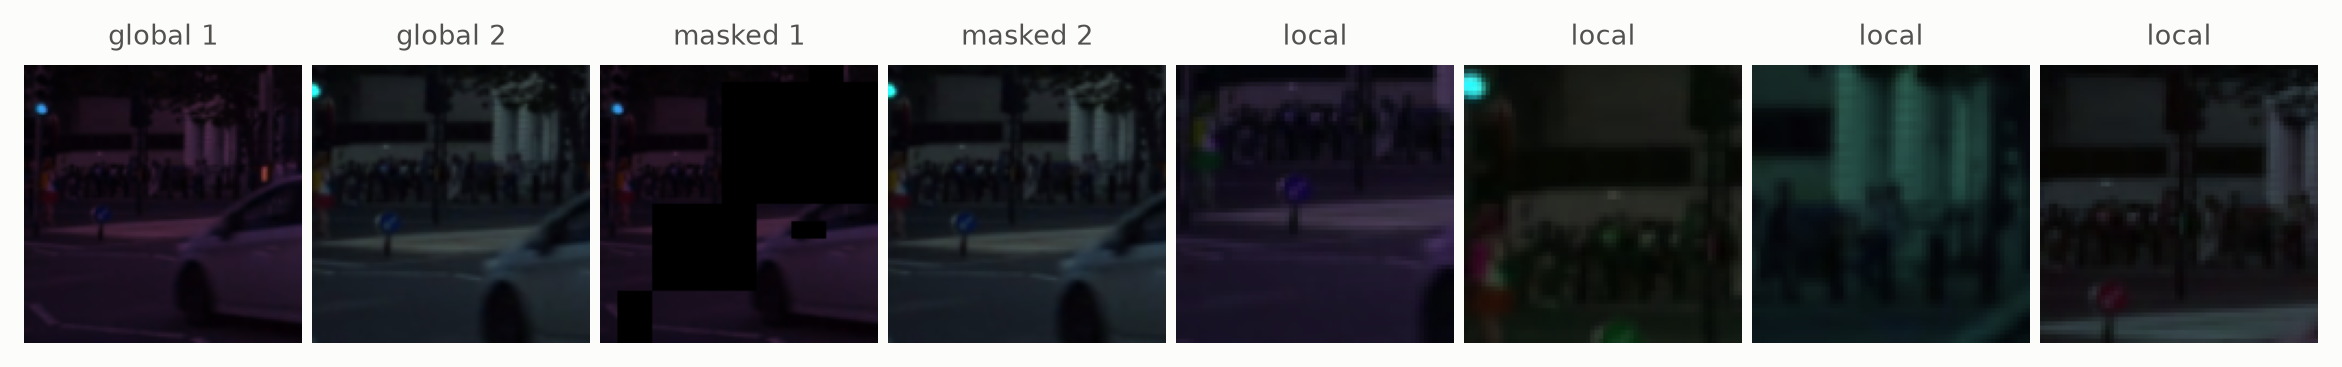

In [3]:
def crop(x, scale, size):
    """The same random square crop of every image or frame of x (B, C, ..., H, W), resized to size."""
    side = int(x.size(-1) * torch.empty(1).uniform_(*scale).sqrt().item())
    i, j = torch.randint(0, x.size(-1) - side + 1, (2,)).tolist()
    patch = x[..., i : i + side, j : j + side]
    return F.interpolate(patch.flatten(0, -4), size=size, mode="bilinear", antialias=True).unflatten(0, patch.shape[:-3])


def jitter(x):
    """Per-sample channel permutation and gains of x (B, 3, ...), and grayscale for 20% of samples."""
    shape = (len(x), 3) + (1,) * (x.dim() - 2)
    perm = torch.rand(len(x), 3, device=device).argsort(1)
    x = x.gather(1, perm.view(shape).expand_as(x)) * (0.6 + 0.8 * torch.rand(shape, device=device))
    gray = torch.rand((len(x),) + (1,) * (x.dim() - 1), device=device) < 0.2
    return torch.where(gray, x.mean(1, keepdim=True).expand_as(x), x)


def dinov2_views(images):
    """Two global crops (2, B, 3, SIZE, SIZE) and eight local crops (8, B, 3, SIZE / 2, SIZE / 2) of images."""
    global_crops = torch.stack([jitter(crop(images, (0.32, 1.0), SIZE)) for _ in range(2)])
    local_crops = torch.stack([jitter(crop(images, (0.05, 0.32), SIZE // 2)) for _ in range(8)])
    return global_crops, local_crops


def levjepa_views(clips):
    """One global view (B, 3, T, SIZE, SIZE) and four local views (B, 3, T, SIZE / 2, SIZE / 2) of clips."""
    return jitter(crop(clips, (0.8, 1.0), SIZE)), [jitter(crop(clips, (0.25, 0.5), SIZE // 2)) for _ in range(4)]


masker = BlockwiseMask((SIZE // PATCH, SIZE // PATCH))
global_crops, local_crops = dinov2_views(one_frame(london(1, label=torch.tensor([STREET]))[0]))
mask = masker(2, generator=torch.Generator().manual_seed(1)).view(2, SIZE // PATCH, SIZE // PATCH)
masked = global_crops[:, 0] * ~mask.repeat_interleave(PATCH, 1).repeat_interleave(PATCH, 2)[:, None].to(device)
views = torch.cat([global_crops[:, 0], masked, F.interpolate(local_crops[:4, 0], size=SIZE)])
plots.images(views, ["global 1", "global 2", "masked 1", "masked 2"] + ["local"] * 4, ncols=8)

## Train
Both encoders are a ViT with 6 blocks of width 192 and 8 x 8 patches, trained for 1500 steps of 128 samples with AdamW. LeVJEPA trains as in its notebook, dropping 90% of the patch tokens.

DINOv2 follows the reference recipe at this scale: one head of 4096 prototypes shared by DINO and iBOT, a teacher temperature warmed from 0.04 to 0.07 over the first 30% of training, a teacher momentum following a cosine from 0.992 to 1, the prototypes frozen for the first 1% of steps, and gradients clipped to norm 3 for the encoder and head separately.

LeVJEPA trained in 1108 s


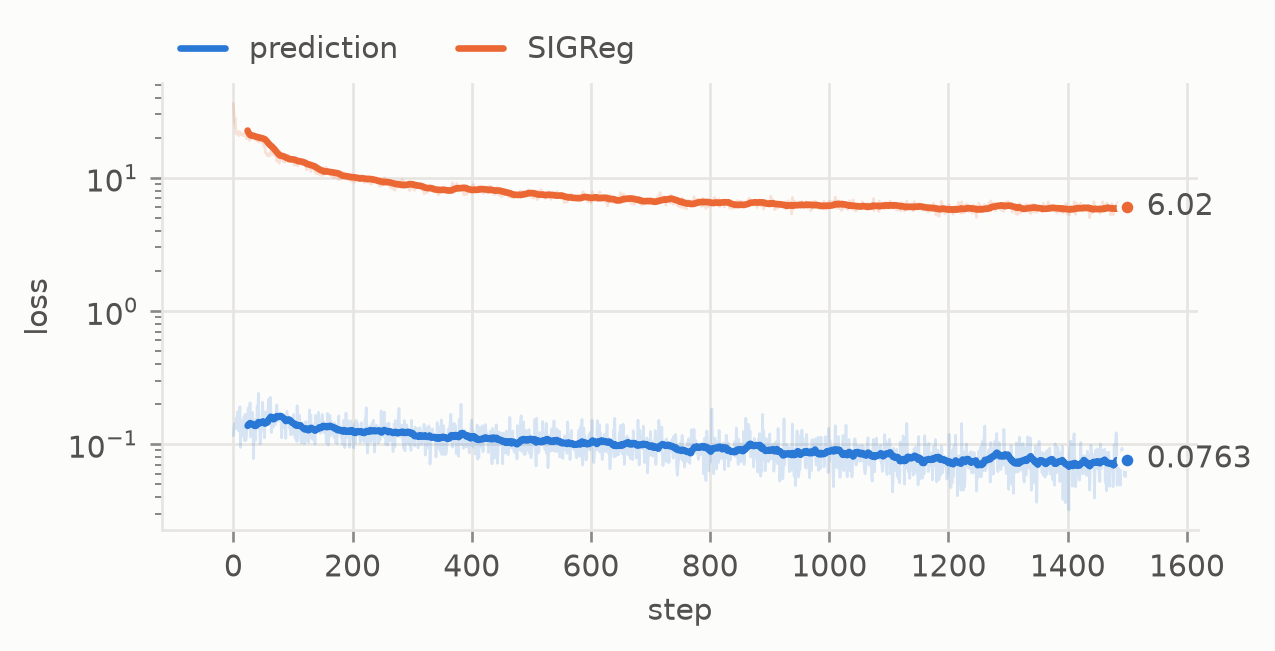

In [4]:
def make_levjepa():
    encoder = LeVJEPAEncoder(img_size=SIZE, num_frames=FRAMES, token_drop=0.9, **VIT)
    return LeVJEPA(encoder, MLP([192, 512, 64], norm=nn.BatchNorm1d), lamb=0.02).to(device)


def make_dinov2():
    head = DINOHead(192, num_prototypes=4096, hidden_dim=1024, bottleneck_dim=256)
    return DINOv2(DINOv2Encoder(img_size=SIZE, **VIT), head).to(device)


def optimizer(model):
    return torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=5e-4, weight_decay=0.04)


levjepa = make_levjepa()
opt, log, start = optimizer(levjepa), {"prediction": [], "SIGReg": []}, time.time()
for step in range(STEPS):
    out = levjepa(*levjepa_views(london(BATCH)[0]))
    opt.zero_grad()
    out["loss"].backward()
    opt.step()
    log["prediction"].append(out["pred_loss"].item())
    log["SIGReg"].append(out["sigreg_loss"].item())
print(f"LeVJEPA trained in {time.time() - start:.0f} s")
plots.curves(log)

DINOv2 trained in 2505 s


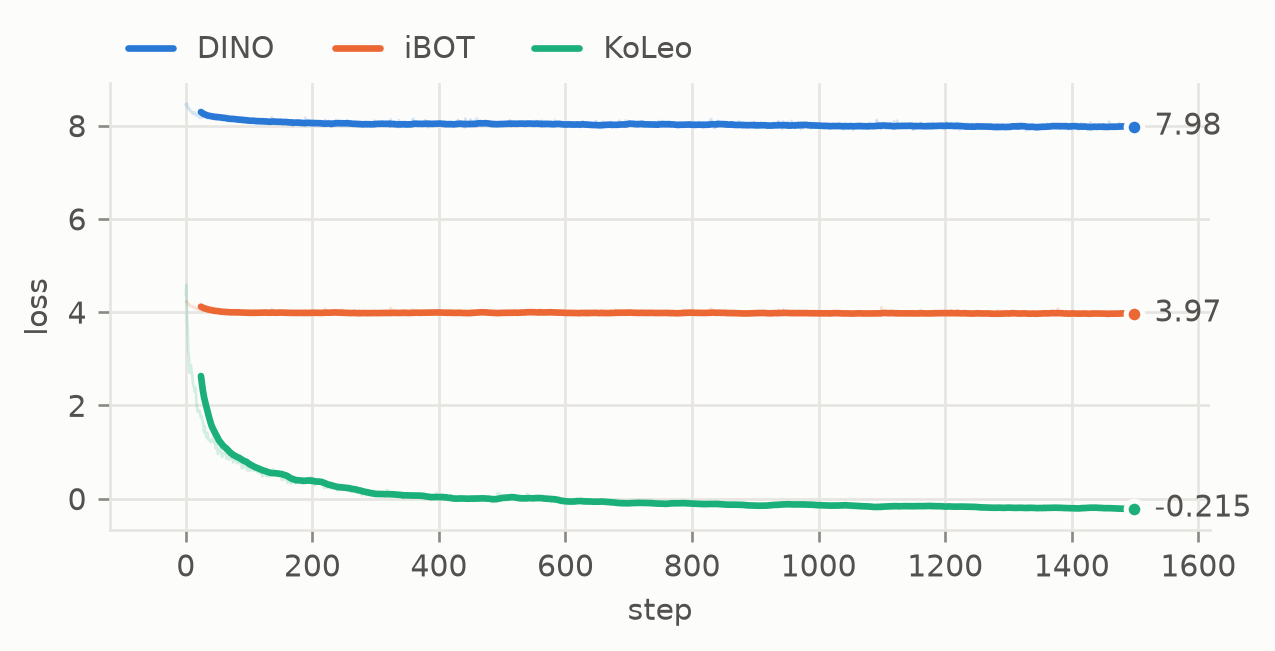

In [5]:
def teacher_temp(step, start=0.04, end=0.07, warmup=0.3 * STEPS):
    return start + (end - start) * min(step / warmup, 1.0)


def teacher_momentum(step, start=0.992):
    return 1 - (1 - start) * (1 + math.cos(math.pi * step / STEPS)) / 2


dinov2 = make_dinov2()
opt, log, start = optimizer(dinov2), {"DINO": [], "iBOT": [], "KoLeo": []}, time.time()
for step in range(STEPS):
    global_crops, local_crops = dinov2_views(one_frame(london(BATCH)[0]))
    mask = masker(2 * BATCH).view(2, BATCH, -1).to(device)
    out = dinov2(global_crops, local_crops, mask, teacher_temp=teacher_temp(step))
    opt.zero_grad()
    out["loss"].backward()
    if step < 0.01 * STEPS:
        dinov2.head.prototypes.zero_grad(set_to_none=True)
    for part in dinov2.encoder, dinov2.head:
        nn.utils.clip_grad_norm_(part.parameters(), 3.0)
    opt.step()
    dinov2.update_teacher(teacher_momentum(step))
    for name, key in zip(log, ("dino_loss", "ibot_loss", "koleo_loss")):
        log[name].append(out[key].item())
print(f"DINOv2 trained in {time.time() - start:.0f} s")
plots.curves(log, logy=False)

## What the features know
Both are evaluated frozen, on the `[cls]` embedding of the same 3072 fresh clips (2560 to fit, 512 to test), color-jittered as in training: a linear probe and a k-NN vote of the 20 nearest clips for the scene (chance 1/4) and the region (chance 1/12), and RankMe, the effective rank of the embeddings out of 192. LeVJEPA reads each clip; DINOv2, an image model, embeds every frame with its teacher, the encoder it releases, and averages them. Each model is compared to its encoder at random initialization.

In [6]:
def per_frame(encoder, clips):
    """An image encoder's [cls] (B, D) of clips (B, 3, T, H, W), averaged over frames."""
    return encoder(clips.transpose(1, 2).flatten(0, 1))[:, 0].unflatten(0, (len(clips), clips.size(2))).mean(1)


def embed(encode, clips):
    """Embeddings (N, D) of clips, 64 at a time."""
    with torch.no_grad():
        return torch.cat([encode(c) for c in clips.split(64)])


def probe_scores(z, y, fit=2560):
    """Linear-probe and k-NN accuracy, fitting on the first fit embeddings and testing on the rest."""
    train, test = (z[:fit], y[:fit]), (z[fit:], y[fit:])
    return metrics.linear_probe(*train, *test).score, metrics.knn_accuracy(*train, *test).score


levjepa.eval(), dinov2.eval()
recompute_batchnorm(levjepa, [london(BATCH)[0] for _ in range(16)], lambda x: levjepa.projector(levjepa.encode(x)))
clips, scene, region = london(3072, generator=torch.Generator(device).manual_seed(7))
torch.manual_seed(11)
clips = torch.cat([jitter(c) for c in clips.split(128)])

random_dinov2, random_levjepa = make_dinov2().encoder.eval(), make_levjepa().encoder.eval()
encoders = {
    "DINOv2, random init": lambda c: per_frame(random_dinov2, c),
    "DINOv2": lambda c: per_frame(dinov2.teacher_encoder, c),
    "LeVJEPA, random init": lambda c: random_levjepa(c)[:, 0],
    "LeVJEPA": lambda c: levjepa.encoder(c)[:, 0],
}
print(f"{'':22s}{'scene: linear':>15s}{'k-NN':>7s}{'region: linear':>16s}{'k-NN':>7s}{'RankMe':>8s}")
for name, encode in encoders.items():
    z = embed(encode, clips)
    scores = probe_scores(z, scene) + probe_scores(z, region)
    print(f"{name:22s}" + "".join(f"{s:{w}.1%}" for s, w in zip(scores, (15, 7, 16, 7))) + f"{metrics.rankme(z):8.1f}")

                        scene: linear   k-NN  region: linear   k-NN  RankMe


DINOv2, random init             84.0%  63.5%           53.9%  31.1%     6.9


DINOv2                          97.5%  96.3%           81.4%  74.6%   100.1


LeVJEPA, random init            81.2%  61.3%           51.0%  30.1%     5.1


LeVJEPA                        100.0% 100.0%           92.6%  83.8%    26.7


## Patch features
The [DINOv2](https://arxiv.org/abs/2304.07193) and [LeVJEPA](https://levjepa.github.io/) papers both show frozen patch tokens through PCA: their three leading components, as RGB. Each model reads a whole photo, 384 x 512 (48 x 64 patches): DINOv2 resizes its position embeddings, LeVJEPA computes RoPE on the photo's grid and reads it as a one-frame clip. Each photo and model gets its own PCA.

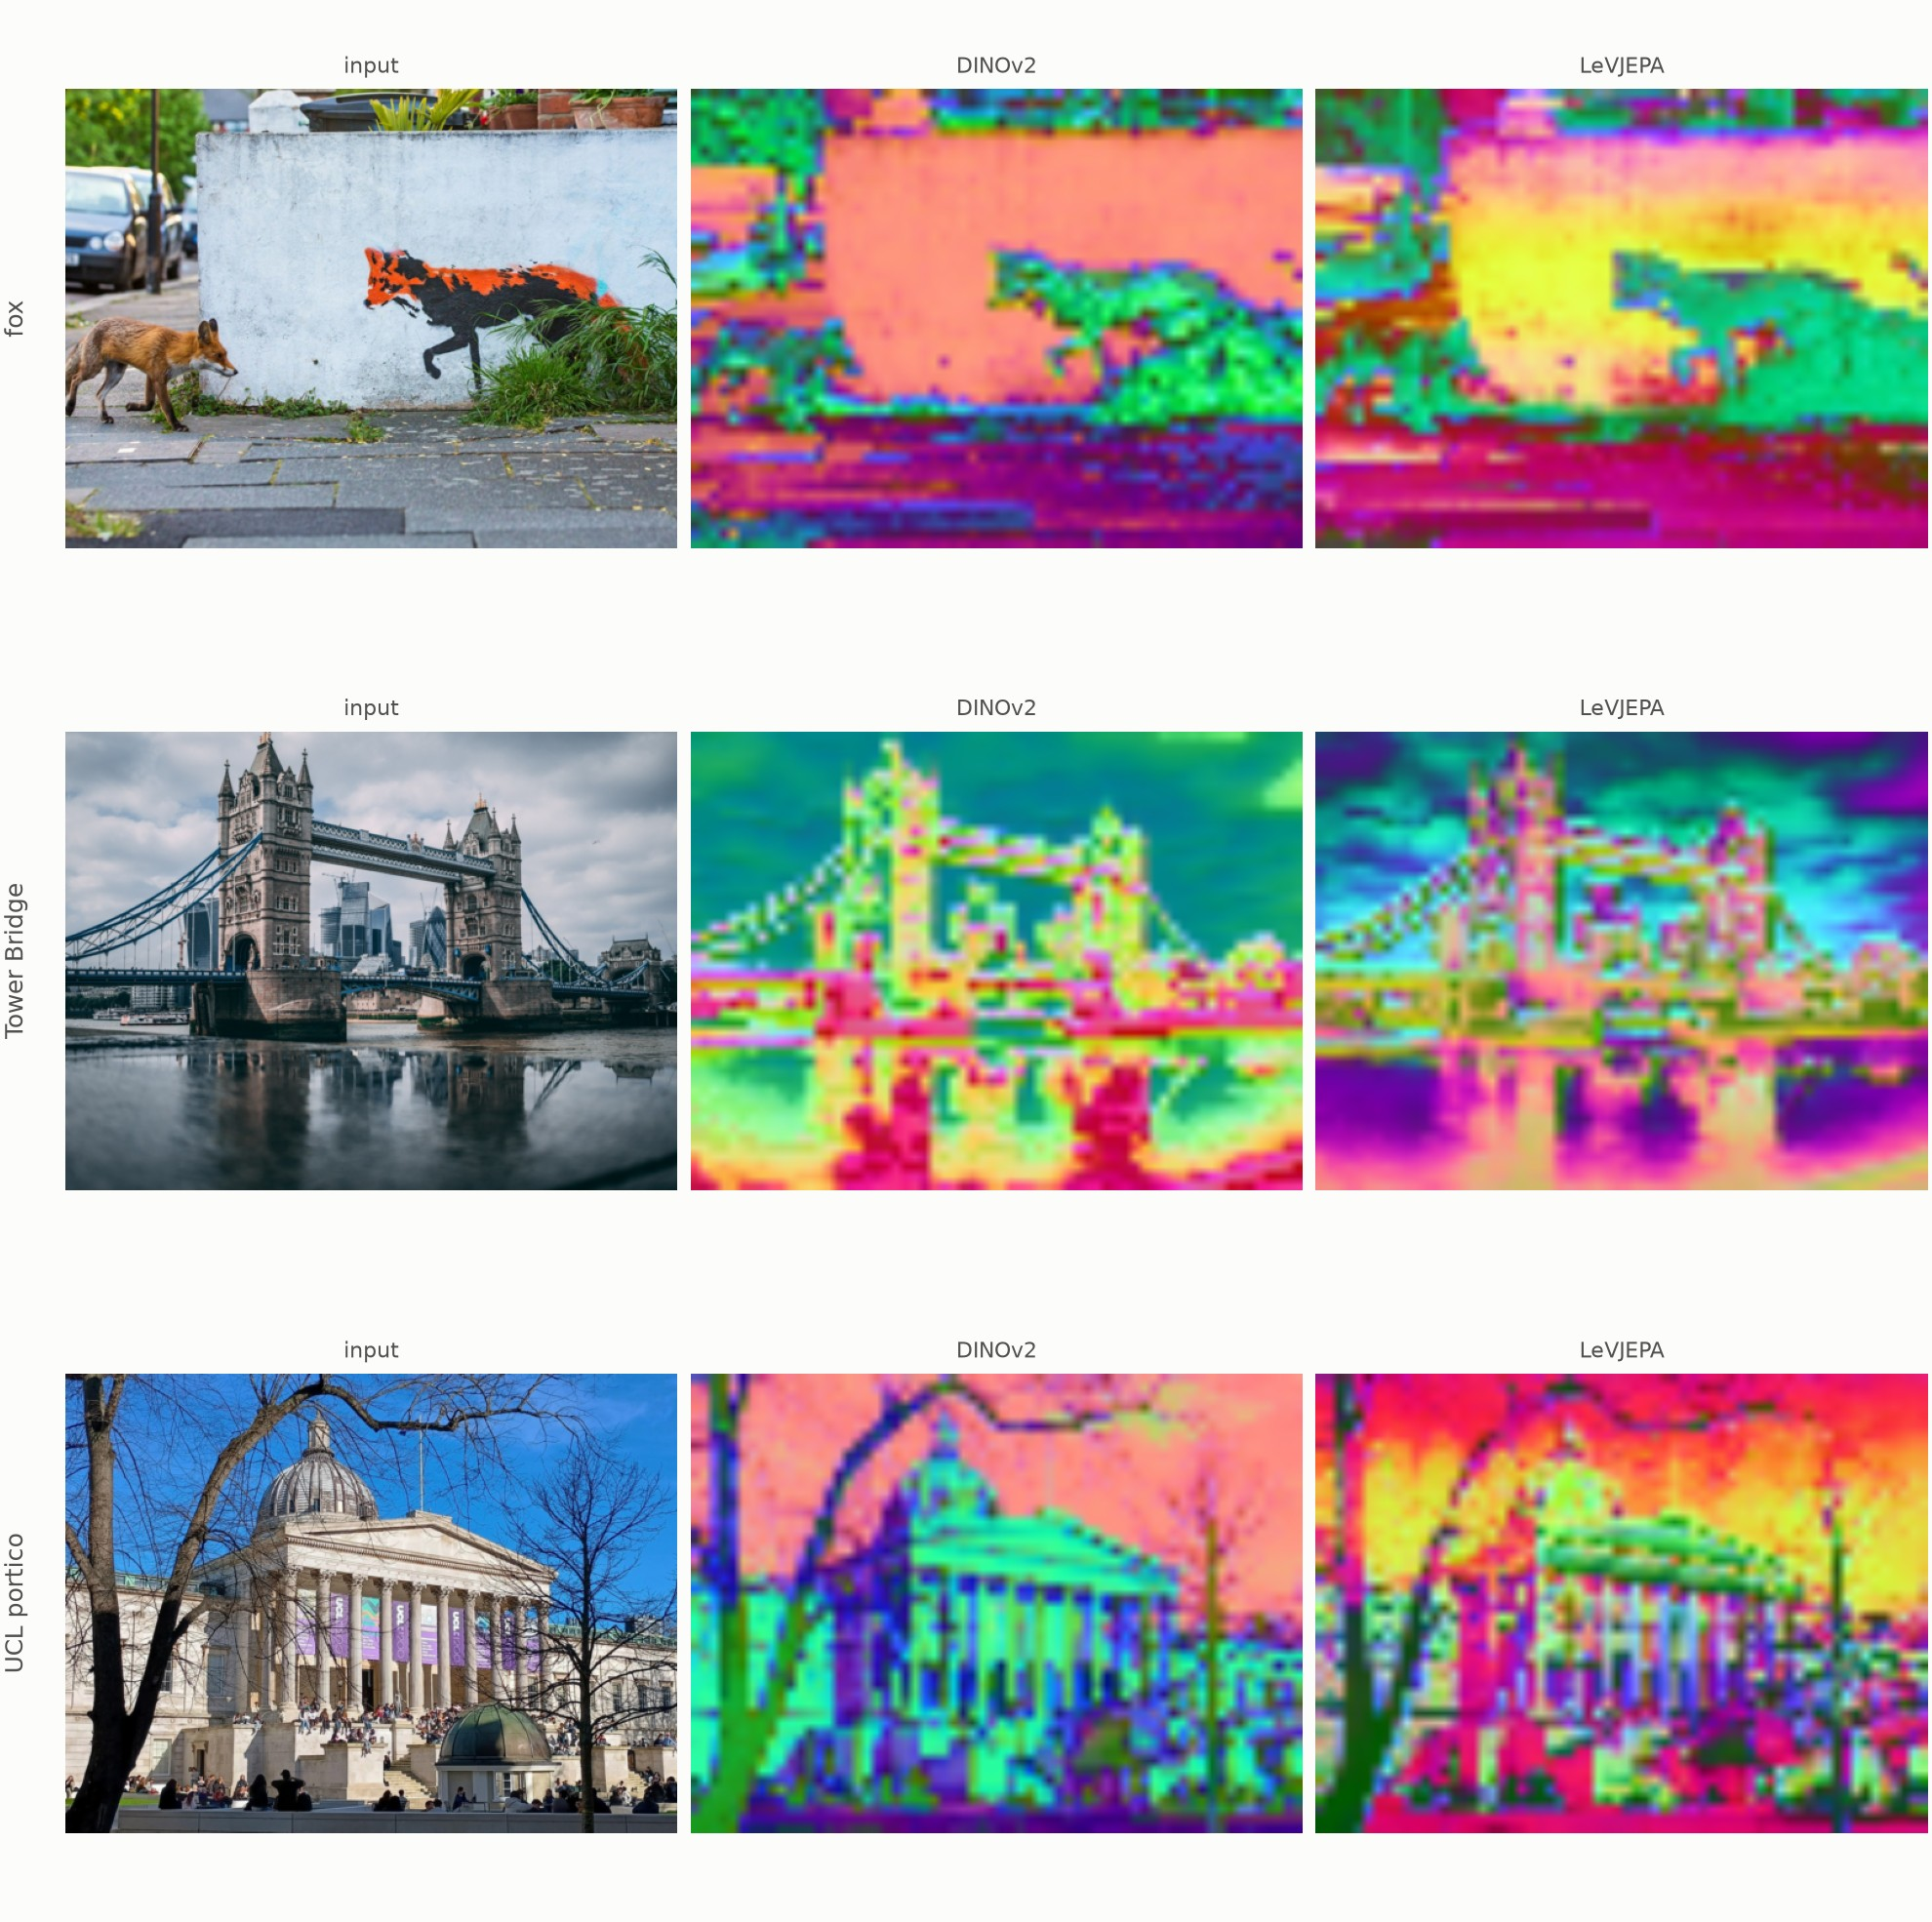

In [7]:
def dinov2_tokens(frames):
    """DINOv2 teacher patch tokens (T, h, w, D) of frames (T, 3, H, W), 8 at a time."""
    with torch.no_grad():
        tokens = torch.cat([dinov2.teacher_encoder(f)[:, 1:] for f in frames.split(8)])
    return tokens.view(len(frames), frames.size(-2) // PATCH, frames.size(-1) // PATCH, -1)


def levjepa_tokens(frames):
    """LeVJEPA patch tokens (T, h, w, D) of frames (T, 3, H, W), encoded FRAMES at a time."""
    with torch.no_grad():
        tokens = torch.cat([levjepa.encoder(clip.transpose(0, 1)[None])[0, 1:] for clip in frames.split(FRAMES)])
    return tokens.view(len(frames), frames.size(-2) // PATCH, frames.size(-1) // PATCH, -1)


def pca_rgb(tokens):
    """The three leading principal components of tokens (..., D), each scaled to [0, 1], as (..., 3)."""
    flat = tokens.flatten(0, -2) - tokens.flatten(0, -2).mean(0)
    pcs = flat @ torch.pca_lowrank(flat, q=3, center=False)[2]
    lo, hi = pcs.quantile(0.01, dim=0), pcs.quantile(0.99, dim=0)
    return ((pcs - lo) / (hi - lo)).clamp(0, 1).view(*tokens.shape[:-1], 3)


def upsample(maps, size):
    """Maps (N, h, w, 3) to images (N, 3, *size)."""
    return F.interpolate(maps.permute(0, 3, 1, 2).float(), size=size, mode="bilinear", align_corners=False).clamp(0, 1)


size = photos.shape[-2:]
dinov2_pca = upsample(torch.cat([pca_rgb(dinov2_tokens(photo[None])) for photo in photos]), size)
levjepa_pca = upsample(torch.cat([pca_rgb(levjepa_tokens(photo[None])) for photo in photos]), size)
grid = torch.stack([photos, dinov2_pca, levjepa_pca], 1).flatten(0, 1)
jpeg(plots.images(grid, ["input", "DINOv2", "LeVJEPA"] * len(photos), ncols=3, size=3.2, rows=list(SCENES)[:STREET]))

## Patch features on the street
The street footage at 432 x 768 (54 x 96 patches), with one PCA per model fitted over every frame, so a color means the same thing throughout.

DINOv2 encodes each frame on its own. LeVJEPA encodes 8 frames at a time, each patch attending its own frame and the earlier ones. The printed correlation measures how much each model's patch tokens move with the pixels from one frame to the next.

In [8]:
frames = street[::STRIDE]
frames = frames[: len(frames) // FRAMES * FRAMES]  # (T, 3, 432, 768)
tokens = {"DINOv2": dinov2_tokens(frames), "LeVJEPA": levjepa_tokens(frames)}

pixels = F.avg_pool2d((frames[1:] - frames[:-1]).abs().mean(1, keepdim=True), PATCH).flatten()
for name, t in tokens.items():
    change = (t[1:] - t[:-1]).norm(dim=-1).flatten()
    print(f"{name}: correlation of token change with pixel change {torch.corrcoef(torch.stack([change, pixels]))[0, 1]:.2f}")

size = frames.shape[-2:]
video({"footage": frames} | {name: upsample(pca_rgb(t), size) for name, t in tokens.items()})

DINOv2: correlation of token change with pixel change 0.82
LeVJEPA: correlation of token change with pixel change 0.83
